<a href="https://colab.research.google.com/github/PixelSer/PythonAiFinalProject/blob/main/FinPyAi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

display(df.head())

df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)
display(df_encoded.head())


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin = lin_reg.predict(X_test)

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train)
y_pred_poly = poly_reg.predict(X_test_poly)

tree_reg = DecisionTreeRegressor(max_depth=4, random_state=42)
tree_reg.fit(X_train, y_train)
y_pred_tree = tree_reg.predict(X_test)

print(f"R2 Линейной регрессии: {r2_score(y_test, y_pred_lin):.4f}")
print(f"R2 Полиномиальной регрессии: {r2_score(y_test, y_pred_poly):.4f}")
print(f"R2 Дерева решений: {r2_score(y_test, y_pred_tree):.4f}")

R2 Линейной регрессии: 0.7836
R2 Полиномиальной регрессии: 0.8666
R2 Дерева решений: 0.8641


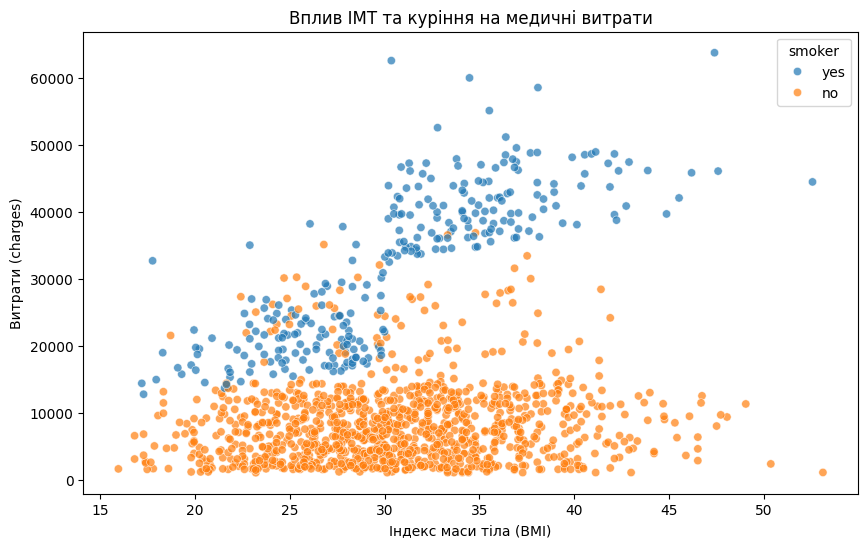

Висновок для звіту:
На графіку чітко видно нелінійний ефект (синергію): у некурящих ростуть витрати при високому BMI дуже повільно,
а у курців при BMI > 30 витрати стрімко злітають вгору (утворюється крутий стрибок).
Звичайна лінійна модель сумує ефекти окремо (коефіцієнт куріння + коефіцієнт BMI), тому вона не здатна
зрозуміти цей сплеск від їхньої комбінації без поліноміальних фіч або дерева рішень.


In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.7)
plt.title("Вплив ІМТ та куріння на медичні витрати")
plt.xlabel("Індекс маси тіла (BMI)")
plt.ylabel("Витрати (charges)")
plt.show()

print("Висновок для звіту:")
print("На графіку чітко видно нелінійний ефект (синергію): у некурящих ростуть витрати при високому BMI дуже повільно,")
print("а у курців при BMI > 30 витрати стрімко злітають вгору (утворюється крутий стрибок).")
print("Звичайна лінійна модель сумує ефекти окремо (коефіцієнт куріння + коефіцієнт BMI), тому вона не здатна")
print("зрозуміти цей сплеск від їхньої комбінації без поліноміальних фіч або дерева рішень.")

In [ ]:
def simulate_client(age, bmi, children, smoker_status):

    sample = pd.DataFrame({
        'age': [age],
        'bmi': [bmi],
        'children': [children],
        'sex_male': [1],
        'smoker_yes': [1 if smoker_status == 'yes' else 0],
        'region_northwest': [0],
        'region_southeast': [1],
        'region_southwest': [0]
    })

    pred_lin = lin_reg.predict(sample)[0]
    sample_poly = poly.transform(sample)
    pred_poly = poly_reg.predict(sample_poly)[0]

    return pred_poly

age, bmi, children = 30, 31.0, 1

cost_no_smoke = simulate_client(age, bmi, children, 'no')
cost_smoke = simulate_client(age, bmi, children, 'yes')

print(ж := f"Для клієнта (вік {age}, ІМТ {bmi}):")
print(f"  - Якщо НЕ курить: ~{cost_no_smoke:.2f} $")
print(f"  - Якщо КУРИТЬ:    ~{cost_smoke:.2f} $")
print(f"Різниця через куріння складає майже: ~{cost_smoke - cost_no_smoke:.2f} $ на рік!")

Для клієнта (вік 30, ІМТ 31.0):
  - Якщо НЕ курить: ~5873.03 $
  - Якщо КУРИТЬ:    ~29606.44 $
Різниця через куріння складає майже: ~23733.41 $ на рік!
